Model from Blackwood, Hastings & Mumby (2012), *Theor Ecol* 5:105-114 (Eqs. 4-8, with grazing $g(P)=P$ after rescaling).

State variables (fractions of seabed, $M+C+T=1$, and scaled parrotfish abundance $P$):

$$\frac{dM}{dt}=aMC-\frac{P\,M}{M+T}+\gamma MT,\qquad
\frac{dC}{dt}=rTC-dC-aMC,\qquad
\frac{dP}{dt}=sP\left(1-\frac{P}{K(C)}\right)-fP$$

with $T=1-M-C$ and two habitat scenarios for the parrotfish carrying capacity:

* **Food-limited** (structure intact, e.g. after bleaching): $K(C)=1-zC$
* **Habitat-limited** (structure flattened, e.g. after a hurricane): $K(C)=C$


In [1]:
# Import relevant packages (same as the course notebook)
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# Parameters (Table 1 of the paper)
a, gamma, r, d = 0.1, 0.8, 1.0, 0.44
s, z = 0.49, 0.5
C_STAR = (r - d) / r          # 0.56, maximum coral equilibrium
print("Coral-dominated equilibrium C* =", C_STAR)

Coral-dominated equilibrium C* = 0.56


## Numerical methods

The course notebook's Euler and RK4 functions handle a **single** equation $dx/dt=f(t,x)$. Our model is a **system** of three coupled equations, so the state $x$ becomes a vector $(M,C,P)$. The only change is that `soln` is now a table with one row per time step and one column per variable. The update formulas are unchanged:

* **Euler:** $x_{n+1}=x_n+h\,f(t_n,x_n)$ (first-order accurate)
* **RK4:** $x_{n+1}=x_n+\frac{h}{6}(k_1+2k_2+2k_3+k_4)$ (fourth-order accurate)

Throughout, `f` in the solver signature is the **ODE right-hand side**, while the fishing mortality $f$ from the paper is called `fish` in the code.

In [2]:
# Source: .ipynb files from prof. Dodson
def eulers_method(f, x0, tf, h):
    '''
    Euler's method for a SYSTEM dx/dt = f(t, x), where x is a vector.
    Inputs:
        f : function f(t, x) returning the vector of derivatives
        x0: initial condition (list/array)
        tf: final time
        h : step size
    Outputs:
        soln: array of shape (number of times, number of variables)
        t   : numerical time grid
    '''
    t = np.arange(0, tf + h/2, h)
    soln = np.zeros((len(t), len(x0)))
    soln[0] = x0
    for n in range(len(t) - 1):
        soln[n + 1] = soln[n] + h * f(t[n], soln[n])
    return soln, t


def RK4(f, x0, tf, h):
    '''
    Runge-Kutta 4 for a SYSTEM dx/dt = f(t, x), where x is a vector.
    Same inputs/outputs as eulers_method.
    '''
    t = np.arange(0, tf + h/2, h)
    soln = np.zeros((len(t), len(x0)))
    soln[0] = x0
    for n in range(len(t) - 1):
        k1 = f(t[n],       soln[n])
        k2 = f(t[n] + h/2, soln[n] + h*k1/2)
        k3 = f(t[n] + h/2, soln[n] + h*k2/2)
        k4 = f(t[n] + h,   soln[n] + h*k3)
        soln[n + 1] = soln[n] + h * (k1 + 2*k2 + 2*k3 + k4) / 6
    return soln, t

In [3]:
K_FLOOR = 1e-2      # keeps P/K(C) finite when coral -> 0 in the habitat-limited case

def K_food(C):    return 1 - z * C        # food-limited
def K_habitat(C): return C                # habitat-limited

def make_rhs(fish, K):
    '''Return the right-hand side f(t, y) of the model for a given fishing mortality and K(C).'''
    def rhs(t, y):
        M, C, P = y
        T = 1 - M - C
        dM = a*M*C - P*M/(M + T) + gamma*M*T       # grazing term: g(P) * M/(M+T), g(P) = P
        dC = r*T*C - d*C - a*M*C
        dP = s*P*(1 - P/max(K(C), K_FLOOR)) - fish*P
        return np.array([dM, dC, dP])
    return rhs

def M_equilibrium(C0, g0):
    '''Macroalgae level in equilibrium with coral C0 at fixed grazing g0 (as in the paper's Fig. 4).'''
    M = (1 - C0) + (a*C0 - g0/(1 - C0)) / gamma
    return float(np.clip(M, 0, 1 - C0))

def recovery_time(t, C, thresh=0.5):
    '''First time coral cover reaches thresh (NaN if it never does).'''
    idx = np.where(C >= thresh)[0]
    return t[idx[0]] if len(idx) else np.nan

There is no exact solution to compare against, so we test the numerics in two ways: (1) shrink the step size $h$ and check that the answer stops changing, and (2) compare Euler against RK4. The test case is the food-limited recovery below ($f=0.25$, $C_0=0.2$, $P_0=0.05$, $M_0$ at its equilibrium). The reference is RK4 with a very small step, $h=0.005$.

method      h  max |error|  time to C>=0.5 (yr)
ref     0.005            -                65.91
Euler   0.100     3.38e-02                67.00
RK4     0.100     2.00e-08                66.00
Euler   0.050     1.67e-02                66.45
RK4     0.050     1.21e-09                65.95
Euler   0.020     6.63e-03                66.12
RK4     0.020     3.01e-11                65.92
Euler   0.010     3.31e-03                66.01
RK4     0.010     1.76e-12                65.91


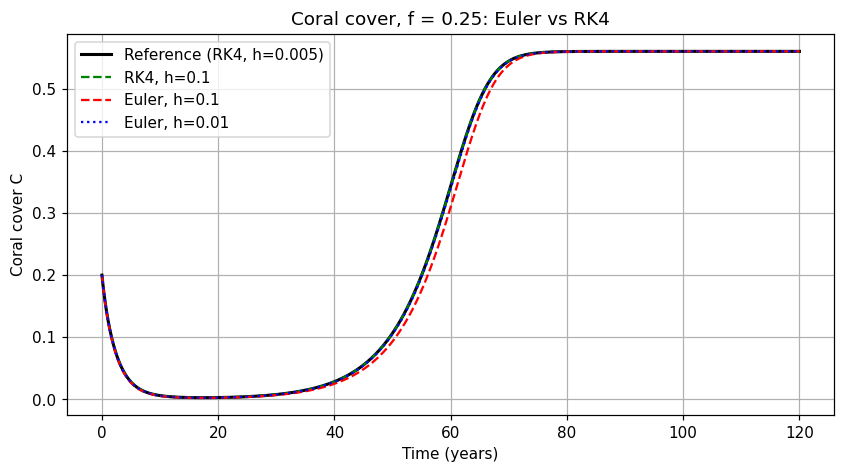

In [4]:
C0, P0 = 0.2, 0.05
M0 = M_equilibrium(C0, P0)
y0 = [M0, C0, P0]
rhs = make_rhs(0.25, K_food)
TF = 120

ref, tref = RK4(rhs, y0, TF, 0.005)          # reference solution
print(f"{'method':6s} {'h':>6s} {'max |error|':>12s} {'time to C>=0.5 (yr)':>20s}")
print(f"{'ref':6s} {0.005:6.3f} {'-':>12s} {recovery_time(tref, ref[:,1]):20.2f}")
results = {}
for h in [0.1, 0.05, 0.02, 0.01]:
    k = int(round(h / 0.005))
    for name, method in [("Euler", eulers_method), ("RK4", RK4)]:
        S, t = method(rhs, y0, TF, h)
        err = np.max(np.abs(S - ref[::k][:len(S)]))
        results[(name, h)] = (S, t)
        print(f"{name:6s} {h:6.3f} {err:12.2e} {recovery_time(t, S[:,1]):20.2f}")

plt.figure(figsize=(9, 4.5))
plt.plot(tref, ref[:, 1], "k", lw=2, label="Reference (RK4, h=0.005)")
plt.plot(results[("RK4", 0.1)][1], results[("RK4", 0.1)][0][:, 1], "g--", label="RK4, h=0.1")
plt.plot(results[("Euler", 0.1)][1], results[("Euler", 0.1)][0][:, 1], "r--", label="Euler, h=0.1")
plt.plot(results[("Euler", 0.01)][1], results[("Euler", 0.01)][0][:, 1], "b:", label="Euler, h=0.01")
plt.xlabel("Time (years)"); plt.ylabel("Coral cover C"); plt.grid()
plt.title("Coral cover, f = 0.25: Euler vs RK4"); plt.legend(); plt.show()

Euler's error shrinks roughly in proportion to $h$ (first order), while RK4's shrinks much faster (fourth order) and is already tiny at $h=0.1$. The recovery time is essentially identical across all RK4 step sizes. We therefore use RK4 with $h=0.02$ for the time-series plots and $h=0.05$ for the long sweep (and re-check the sweep with a smaller step below). Euler is shown only as a comparison.

## Scenario 1: food-limited reef (structure intact), varying fishing effort

Same starting point for every run: low coral ($C_0=0.2$), few parrotfish ($P_0=0.05$), and macroalgae at its equilibrium for that coral level. Only the fishing mortality $f$ changes.

f = 0 (no fishing)           final C=0.560, final M=0.000, final P=0.720, time to C>=0.5: 19.1 yr
f = 0.25                     final C=0.560, final M=0.000, final P=0.353, time to C>=0.5: 65.9 yr
f = 0.45 (heavy fishing)     final C=0.000, final M=0.899, final P=0.081, time to C>=0.5: nan yr


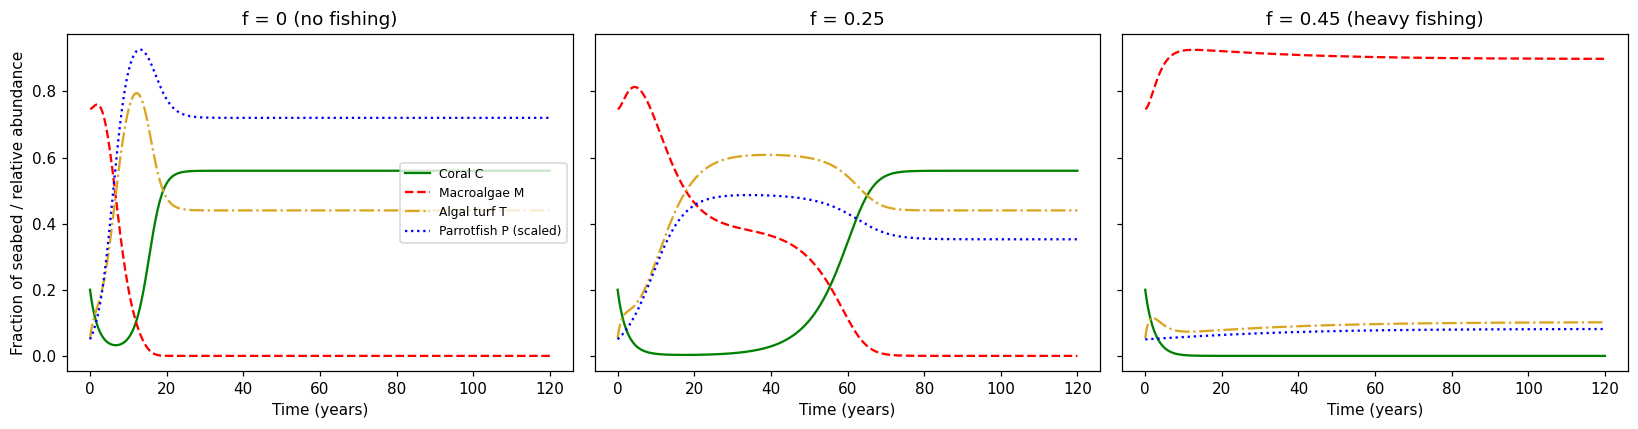

In [5]:
runs = [(0.0, "f = 0 (no fishing)"), (0.25, "f = 0.25"), (0.45, "f = 0.45 (heavy fishing)")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (fish, label) in zip(axes, runs):
    S, t = RK4(make_rhs(fish, K_food), [M0, C0, P0], 120, 0.02)
    M, C, P = S[:, 0], S[:, 1], S[:, 2]
    ax.plot(t, C, "g-", label="Coral C")
    ax.plot(t, M, "r--", label="Macroalgae M")
    ax.plot(t, 1 - M - C, color="goldenrod", ls="-.", label="Algal turf T")
    ax.plot(t, P, "b:", label="Parrotfish P (scaled)")
    ax.set_title(label); ax.set_xlabel("Time (years)")
    rt = recovery_time(t, C)
    print(f"{label:28s} final C={C[-1]:.3f}, final M={M[-1]:.3f}, final P={P[-1]:.3f}, time to C>=0.5: {rt:.1f} yr")
axes[0].set_ylabel("Fraction of seabed / relative abundance")
axes[0].legend(loc="center right", fontsize=8)
plt.tight_layout(); plt.show()

With $f=0$ and $f=0.25$ the reef recovers to the coral-dominated state $(M,C,T)=(0,\,0.56,\,0.44)$, but low fishing recovers far faster (about 19 vs 66 years). With $f=0.45$ (above the critical effort of about 0.37 reported in the paper) the grazers can never rebuild enough, macroalgae wins, and coral collapses.

Two checks against theory. At equilibrium $P^*=K(C^*)(1-f/s)$: with $K(0.56)=0.72$ this gives $0.72$ at $f=0$ and $0.353$ at $f=0.25$, matching the printed values. In the collapsed state $C\approx0$, so $K\approx1$ and $P^*=1-0.45/0.49\approx0.082$, matching the printed $P\approx0.081$.

Note the initial dip in coral in the recovering cases: macroalgae (75% cover) overgrows coral until parrotfish numbers rebuild. The middle panel's plateau in $P$ near 0.49 ($=1-f/s$) sits just above the recovery threshold $g_{crit1}\approx0.39$, which is why recovery is so slow at $f=0.25$.

## Scenario 2: habitat-limited reef (structure lost), alternative stable states

When $K(C)=C$ the grazers depend on coral for shelter, which creates a positive feedback (more coral -> more fish -> more grazing -> more coral). Here the *initial state* decides the outcome even with identical fishing effort.

Disturbance cleared the macroalgae     final C=0.560, M=0.000, P=0.560
Macroalgae already established         final C=0.000, M=0.987, P=0.010


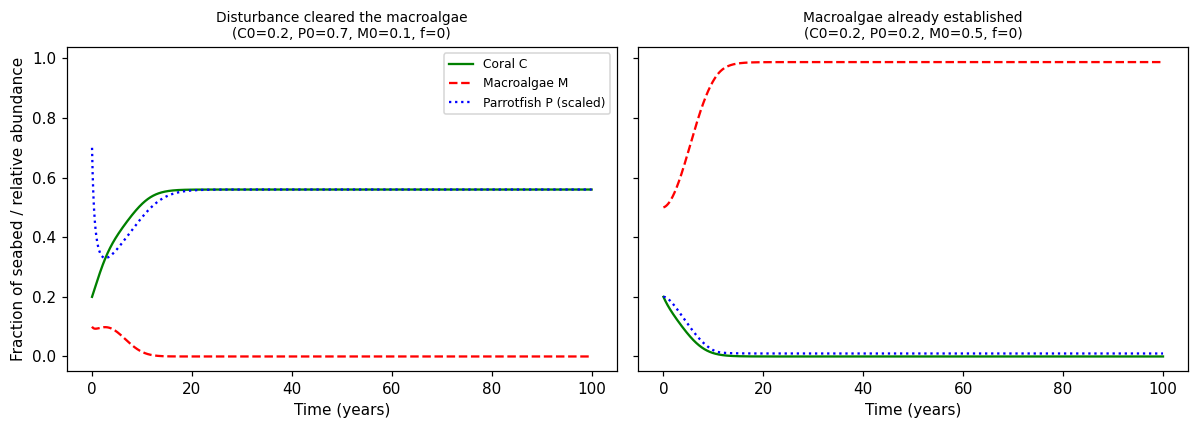

In [10]:
fish = 0
cases = [
    ("Disturbance cleared the macroalgae", 0.20, 0.70, 0.1),
    ("Macroalgae already established",     0.20, 0.20, 0.5),
]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (label, C0_, P0_, M0_) in zip(axes, cases):
    S, t = RK4(make_rhs(fish, K_habitat), [M0_, C0_, P0_], 100, 0.02)
    M, C, P = S[:, 0], S[:, 1], S[:, 2]
    ax.plot(t, C, "g-", label="Coral C"); ax.plot(t, M, "r--", label="Macroalgae M")
    ax.plot(t, P, "b:", label="Parrotfish P (scaled)")
    ax.set_title(f"{label}\n(C0={C0_}, P0={P0_}, M0={M0_}, f={fish})", fontsize=9)
    ax.set_xlabel("Time (years)")
    print(f"{label:38s} final C={C[-1]:.3f}, M={M[-1]:.3f}, P={P[-1]:.3f}")
axes[0].set_ylabel("Fraction of seabed / relative abundance"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Two reefs with the *same* parameters, the *same* coral and parrotfish, and *no fishing* end in different places purely because of how much macroalgae they start with (established macroalgae crowds out coral recruitment, so the grazers lose their habitat before they can rebuild). This is the alternative-stable-states / hysteresis behavior that makes habitat loss so hard to reverse by reducing fishing alone.

(The left panel is the paper's "best possible" start, as in its Fig. 2b: with no macroalgae, coral grows logistically to 0.56 regardless of grazing. In the collapsed run, $P$ settles at 0.01 rather than 0 only because of the numerical floor `K_FLOOR`; this has no effect on the outcome, since grazing of 0.01 is far below the thresholds of 0.18 and 0.39.)

## Long-term behavior vs. fishing effort

For each fishing level we simulate for a long time from a *degraded* start and from a *healthy* start and record the final coral cover (degraded = macroalgae-dominated with little coral and few grazers; healthy = high coral, abundant grazers, a little macroalgae). Where the two curves disagree, the system has two stable states (hysteresis). This is a simulation-based stand-in for the paper's bifurcation diagram (Fig. 3): it samples two starting states per $f$ and does not show the unstable branch.

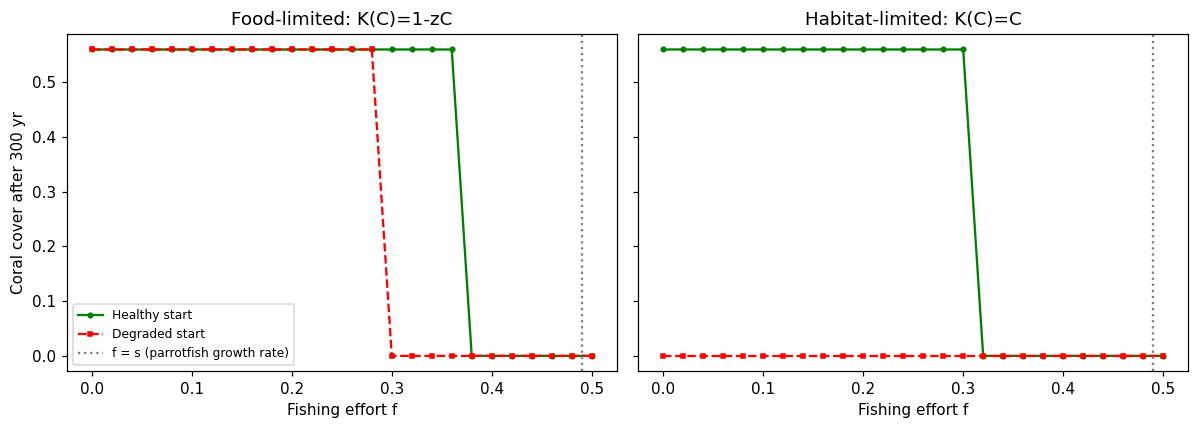

Largest f that still ends in the coral state (step size in f is 0.02):
  food-limited:    degraded start 0.28 | healthy start 0.36
  habitat-limited: degraded start None | healthy start 0.3


In [8]:
f_vals = np.linspace(0, 0.5, 26)

def final_coral(y0, fish, K, tf=300, h=0.05):
    S, t = RK4(make_rhs(fish, K), y0, tf, h)
    return S[-1, 1]

def sweep(K, degraded, healthy, h=0.05):
    return (np.array([final_coral(degraded, fish, K, h=h) for fish in f_vals]),
            np.array([final_coral(healthy,  fish, K, h=h) for fish in f_vals]))

deg_food = [M_equilibrium(0.2, 0.05), 0.2, 0.05]
deg_hab  = [0.5, 0.2, 0.2]
healthy  = [0.1, 0.5, 0.5]

deg_F, hea_F = sweep(K_food,    deg_food, healthy)
deg_H, hea_H = sweep(K_habitat, deg_hab,  healthy)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (deg, hea, title) in zip(axes, [(deg_F, hea_F, "Food-limited: K(C)=1-zC"),
                                        (deg_H, hea_H, "Habitat-limited: K(C)=C")]):
    ax.plot(f_vals, hea, "g-o", ms=3, label="Healthy start")
    ax.plot(f_vals, deg, "r--s", ms=3, label="Degraded start")
    ax.axvline(s, color="gray", ls=":", label="f = s (parrotfish growth rate)")
    ax.set_title(title); ax.set_xlabel("Fishing effort f")
axes[0].set_ylabel("Coral cover after 300 yr"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

def largest_f_with_coral(curve):
    ok = f_vals[curve > 0.28]          # coral above half of C* counts as 'coral state'
    return ok.max() if len(ok) else None

print("Largest f that still ends in the coral state (step size in f is 0.02):")
print("  food-limited:    degraded start", largest_f_with_coral(deg_F), "| healthy start", largest_f_with_coral(hea_F))
print("  habitat-limited: degraded start", largest_f_with_coral(deg_H), "| healthy start", largest_f_with_coral(hea_H))

In [9]:
# Robustness check: repeat the sweep with a smaller time step and compare
deg_F2, hea_F2 = sweep(K_food,    deg_food, healthy, h=0.025)
deg_H2, hea_H2 = sweep(K_habitat, deg_hab,  healthy, h=0.025)
same = all(np.array_equal(x > 0.28, y > 0.28) for x, y in
           [(deg_F, deg_F2), (hea_F, hea_F2), (deg_H, deg_H2), (hea_H, hea_H2)])
print("Coral-state vs collapsed classification identical at h=0.05 and h=0.025:", same)

Coral-state vs collapsed classification identical at h=0.05 and h=0.025: True


### What the sweep shows

- **Food-limited:** Below $f \approx 0.30$, both initial conditions recover. Between $0.30$ and $0.37$, outcomes depend on initial conditions (hysteresis). Above $0.37$, both collapse.
- **Habitat-limited:** Degraded reefs never recover naturally, even with zero fishing, while healthy reefs persist until $f \approx 0.33$.

### Interpretation

Fishing reduces parrotfish abundance and grazing, allowing macroalgae to outcompete coral. Near critical fishing thresholds, recovery slows significantly.

Under habitat limitation, coral loss reduces fish shelter and grazing, creating a positive feedback that makes recovery dependent on initial conditions.

**Management implications:** Structurally intact reefs are more resilient to fishing. Degraded reefs require active restoration alongside fishing restrictions, while slow recovery highlights the importance of marine protected areas.